In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lmfit import Model


In [7]:

HDF_PATH = "LacI landscape data.hdf"   # adjust to where your file is  
# 12 IPTG concentrations (umol/L): one row without IPTG, then 2-fold dilutions 2 - 2048
# (from the paper's methods). Assumes the array columns are in this ascending order.
IPTG = np.array([0, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048], dtype=float)

MIN_COUNTS = 5000   # quality threshold used by the authors for single-substitution analysis
PLASMID_REGIONS = ["pacbio_tetA_mutations", "pacbio_KAN_mutations", "pacbio_Ori_mutations",
                   "pacbio_YFP_mutations", "pacbio_insulator_mutations"]



In [8]:

# ---------------------------------------------------------------- model
def log_hill(x, log_g0, log_ginf, log_ec50, n):
    """log10 of the Hill equation. Parameters are log10 values, like the authors' columns."""
    g0, ginf, ec50 = 10 ** log_g0, 10 ** log_ginf, 10 ** log_ec50
    return np.log10(g0 + (ginf - g0) * x ** n / (ec50 ** n + x ** n))


def fit_curve(med, sd):
    model = Model(log_hill)
    p = model.make_params(
        log_g0=dict(value=med[0], min=1.5, max=4.7),
        log_ginf=dict(value=med[-1], min=1.5, max=4.7),
        log_ec50=dict(value=2.0, min=-1, max=4.6),
        n=dict(value=1.5, min=0.3, max=6))
    return model.fit(med, p, x=IPTG, weights=1.0 / sd)



In [9]:

# ---------------------------------------------------------------- data selection
def select_wildtype(df):
    mask = (df["lacI_amino_mutations"] == 0) & (df["hasConfidentCds"].astype(bool))
    mask &= df["total_counts"] > MIN_COUNTS
    for c in PLASMID_REGIONS:
        if c in df.columns:
            mask &= df[c] == 0          # 0 = covered and no mutations (-1 = not covered)
    return df[mask].sort_values("total_counts", ascending=False)


def curve_from_row(row):
    np.asarray(df["sensor_GP_g_quantiles"].iloc[0]).shape
    q = np.asarray(row["sensor_GP_g_quantiles"], dtype=float)   # shape (5, 12)
    med = q[2]                               # 0.5 quantile
    sd = np.maximum((q[4] - q[0]) / 3.29, 0.02)   # 5-95% range -> approx. 1 sd (log10 units)
    return med, sd



15 wild-type barcodes pass the filters

Parameter summary across wild-type barcodes (mean +/- sd):
G0    ours:    270.86 +/-    76.68   authors:    625.17 +/-   143.41   
-mean ratio ours/authors: 0.43
Ginf  ours:  24822.48 +/-  1083.58   authors:  23995.84 +/-   833.13   
-mean ratio ours/authors: 1.03
EC50  ours:    104.51 +/-     8.79   authors:    103.99 +/-     8.61   
-mean ratio ours/authors: 1.01
n     ours:      1.52 +/-     0.17   authors:      1.59 +/-     0.19   
-mean ratio ours/authors: 0.96


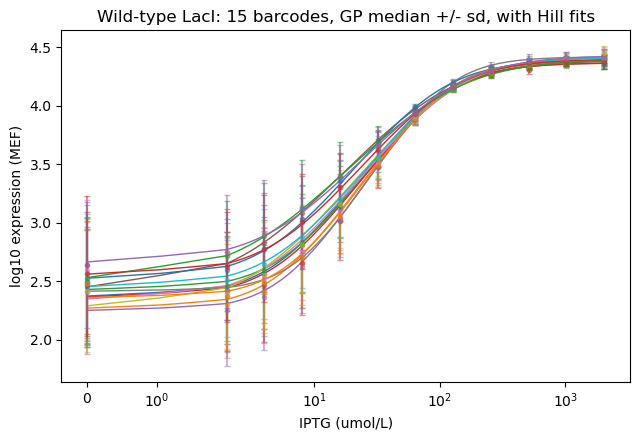

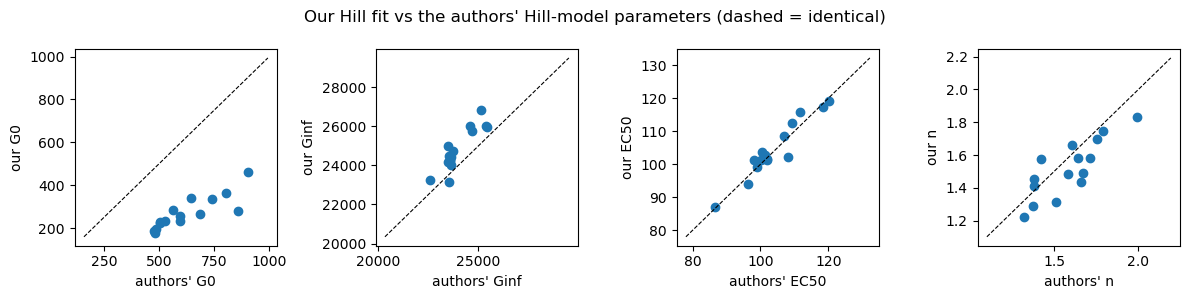

In [10]:


# ---------------------------------------------------------------- analysis
def analyze(df, max_variants=15, outdir="."):
    os.makedirs(os.path.join(outdir, "figures"), exist_ok=True)
    os.makedirs(os.path.join(outdir, "results"), exist_ok=True)

    wt = select_wildtype(df).head(max_variants)
    print(f"{len(wt)} wild-type barcodes pass the filters")
    if len(wt) < 3:
        print("Few barcodes passed: try lowering MIN_COUNTS or dropping the plasmid-region filter.")

    rows, fits = [], []
    for idx, row in wt.iterrows():
        med, sd = curve_from_row(row)
        res = fit_curve(med, sd)
        fits.append((idx, med, sd, res))
        rows.append(dict(
            barcode_row=idx, total_counts=row["total_counts"],
            our_G0=10 ** res.params["log_g0"].value, our_Ginf=10 ** res.params["log_ginf"].value,
            our_EC50=10 ** res.params["log_ec50"].value, our_n=res.params["n"].value,
            auth_G0=10 ** row["log_low_level"], auth_Ginf=10 ** row["log_high_level"],
            auth_EC50=10 ** row["log_ic50"], auth_n=10 ** row["log_n"],
            red_chi2=res.redchi))
    tab = pd.DataFrame(rows)
    tab.to_csv(os.path.join(outdir, "results", "wt_fits.csv"), index=False)

    # ---- summary across wild-type barcodes (replicate spread)
    print("\nParameter summary across wild-type barcodes (mean +/- sd):")
    for name in ["G0", "Ginf", "EC50", "n"]:
        o, a = tab[f"our_{name}"], tab[f"auth_{name}"]
        print(f"{name:5s} ours: {o.mean():9.2f} +/- {o.std():8.2f}   "
              f"authors: {a.mean():9.2f} +/- {a.std():8.2f}   "
              f"\n-mean ratio ours/authors: {(o / a).mean():.2f}")

    # ---- figure 1: curves + fits
    xs = np.concatenate([[0], np.logspace(0, np.log10(2048), 300)])
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for k, (idx, med, sd, res) in enumerate(fits):
        ax.errorbar(IPTG, med, yerr=sd, fmt="o", ms=3, alpha=0.5, capsize=2,
                    color=f"C{k % 10}", label=None)
        ax.plot(xs, res.model.eval(res.params, x=xs), color=f"C{k % 10}", lw=1)
    ax.set_xscale("symlog", linthresh=2)
    ax.set_xlabel("IPTG (umol/L)")
    ax.set_ylabel("log10 expression (MEF)")
    ax.set_title(f"Wild-type LacI: {len(fits)} barcodes, GP median +/- sd, with Hill fits")
    fig.tight_layout()
    fig.savefig(os.path.join(outdir, "figures", "wt_curves_fits.png"), dpi=200)

    # ---- figure 2: our fit vs author's Hill parameters
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    for ax, name in zip(axes, ["G0", "Ginf", "EC50", "n"]):
        a, o = tab[f"auth_{name}"], tab[f"our_{name}"]
        ax.scatter(a, o)
        lo, hi = min(a.min(), o.min()) * 0.9, max(a.max(), o.max()) * 1.1
        ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
        ax.set_xlabel(f"authors' {name}")
        ax.set_ylabel(f"our {name}")
    fig.suptitle("Our Hill fit vs the authors' Hill-model parameters (dashed = identical)")
    fig.tight_layout()
    fig.savefig(os.path.join(outdir, "figures", "ours_vs_authors.png"), dpi=200)
    return tab


if __name__ == "__main__":  
    df = pd.read_hdf(HDF_PATH) 
    analyze(df)  
    plt.show()
    